In [1]:
# ============================================================
# GPU SETUP + CONFIGURATION — RUN FIRST AFTER RESTARTING KERNEL
# ============================================================
import os
GPU_ID = "5"  # DGX physical GPU ID; change only if your assigned GPU differs.
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
from pathlib import Path
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

# -------------------------
# Warwick QU / GlaS config
# -------------------------
ROOT_DIR = "/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED"
IMG_SIZE = (256, 384)  # (height, width); approximates the dataset's landscape aspect ratio
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
AUTOTUNE = tf.data.AUTOTUNE

OUTPUT_DIR = r"/raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.isdir(ROOT_DIR):
    raise FileNotFoundError(
        f"Dataset root not found: {ROOT_DIR}. It must contain train/img, train/mask, "
        "val/img, val/mask, test/img, and test/mask."
    )
for split in ("train", "val", "test"):
    for subfolder in ("img", "mask"):
        folder = os.path.join(ROOT_DIR, split, subfolder)
        if not os.path.isdir(folder):
            raise FileNotFoundError(f"Required folder not found: {folder}")

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("CUDA_VISIBLE_DEVICES:", GPU_ID)
print("Visible TensorFlow GPUs:", gpus)
if not gpus:
    raise RuntimeError(
        "TensorFlow cannot detect a GPU. Restart the kernel and run this cell first; "
        "also check GPU assignment and TensorFlow/CUDA compatibility."
    )
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print(f"Could not enable memory growth for {gpu}: {exc}")
with tf.device("/GPU:0"):
    _gpu_test = tf.matmul(tf.random.normal((64, 64)), tf.random.normal((64, 64)))
print("GPU test:", _gpu_test.shape, _gpu_test.device)
del _gpu_test
print("Dataset root:", ROOT_DIR)
print("Image size (H, W):", IMG_SIZE)
print("Output directory:", OUTPUT_DIR)


2026-10-20 01:07:13.153371: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 01:07:13.153413: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 01:07:13.154693: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow: 2.15.1
CUDA_VISIBLE_DEVICES: 5
Visible TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU test: (64, 64) /job:localhost/replica:0/task:0/device:GPU:0
Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Image size (H, W): (256, 384)
Output directory: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs


In [2]:
# ============================================================
# PAIR IMAGES + MASKS, THEN LOAD / PREPROCESS / AUGMENT
# Dataset layout: ROOT_DIR/{train,val,test}/{img,mask}
# Images such as sample.png pair with masks such as sample_anno.png.
# ============================================================
from pathlib import Path

VALID_EXTS = {".png", ".bmp", ".bm", ".jpg", ".jpeg", ".tif", ".tiff"}


def list_image_files(folder):
    return sorted(
        p for p in Path(folder).iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    )


def image_key(path):
    return Path(path).stem.casefold()


def mask_key(path):
    key = Path(path).stem.casefold()
    # GlaS annotations commonly use a trailing _anno, e.g. testA_47_anno.png.
    if key.endswith("_anno"):
        key = key[:-len("_anno")]
    return key


def get_pairs(split):
    img_dir = Path(ROOT_DIR) / split / "img"
    mask_dir = Path(ROOT_DIR) / split / "mask"
    if not img_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError(
            f"Expected both directories: {img_dir} and {mask_dir}"
        )

    image_files = list_image_files(img_dir)
    mask_files = list_image_files(mask_dir)
    if not image_files:
        raise ValueError(f"No supported image files found in {img_dir}")
    if not mask_files:
        raise ValueError(f"No supported mask files found in {mask_dir}")

    mask_map = {}
    duplicate_keys = []
    for mask_path in mask_files:
        key = mask_key(mask_path)
        if key in mask_map:
            duplicate_keys.append(key)
        else:
            mask_map[key] = mask_path
    if duplicate_keys:
        raise ValueError(
            f"Duplicate mask keys in {mask_dir}: {sorted(set(duplicate_keys))[:10]}"
        )

    pairs = []
    missing_masks = []
    used_masks = set()
    for img_path in image_files:
        key = image_key(img_path)
        mask_path = mask_map.get(key)
        if mask_path is None:
            missing_masks.append(img_path.name)
        else:
            pairs.append((str(img_path), str(mask_path)))
            used_masks.add(mask_path)

    extra_masks = [p.name for p in mask_files if p not in used_masks]
    if missing_masks or extra_masks:
        details = [f"Image/mask pairing issue in split '{split}'."]
        if missing_masks:
            details.append(
                f"Images without matching masks ({len(missing_masks)}): {missing_masks[:12]}"
            )
        if extra_masks:
            details.append(
                f"Masks without matching images ({len(extra_masks)}): {extra_masks[:12]}"
            )
        details.append(
            "Expected matching stems; for example image 'testA_47.png' "
            "and mask 'testA_47_anno.png'. Check that each image and mask "
            "belong to the same split."
        )
        raise ValueError("\n".join(details))

    print(
        f"{split:>5}: images={len(image_files)}, masks={len(mask_files)}, "
        f"matched pairs={len(pairs)}"
    )
    return pairs


train_pairs = get_pairs("train")
val_pairs = get_pairs("val")
test_pairs = get_pairs("test")

if not train_pairs or not val_pairs or not test_pairs:
    raise ValueError("train, val, and test must all contain matched image-mask pairs.")

# Warn if identical image identifiers occur across split directories.
def _pair_ids(pairs):
    return {Path(img_path).stem.casefold() for img_path, _ in pairs}

train_ids, val_ids, test_ids = map(_pair_ids, (train_pairs, val_pairs, test_pairs))
for left_name, left_ids, right_name, right_ids in (
    ("train", train_ids, "val", val_ids),
    ("train", train_ids, "test", test_ids),
    ("val", val_ids, "test", test_ids),
):
    overlap = left_ids & right_ids
    if overlap:
        print(
            f"WARNING: filename IDs overlap between {left_name} and {right_name}: "
            f"{sorted(overlap)[:10]}"
        )

print("\nExample image-mask pairs:")
for image_path, mask_path in (train_pairs[:2] + val_pairs[:1] + test_pairs[:1]):
    print(f"  {Path(image_path).name} <-> {Path(mask_path).name}")


def decode_path(path_value):
    """Convert str/bytes/NumPy scalar paths into Python strings."""
    if isinstance(path_value, np.ndarray):
        path_value = path_value.item()
    if isinstance(path_value, (bytes, np.bytes_)):
        return path_value.decode("utf-8")
    return str(path_value)


def load_image_mask(img_path, mask_path):
    img_path = decode_path(img_path)
    mask_path = decode_path(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA
    )
    image = image.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(
        mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST
    )
    # Masks are binary: background=0, any nonzero foreground=1.
    mask = (mask > 0).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    """Shape-safe geometric augmentation for rectangular images."""
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    # Avoid random 90-degree rotations, which swap H/W for rectangular inputs.
    return image, mask


train: images=133, masks=133, matched pairs=133
  val: images=16, masks=16, matched pairs=16
 test: images=16, masks=16, matched pairs=16

Example image-mask pairs:
  testA_17.png <-> testA_17_anno.png
  testA_18.png <-> testA_18_anno.png
  testA_1.png <-> testA_1_anno.png
  testB_1.png <-> testB_1_anno.png



Dataset sizes:
  Train: 133
  Val  : 16
  Test : 16
Input tensor shape: (256, 384, 3)
Outputs will be saved to: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs
Model: "UNet_Binary_LearnableKernel"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 384, 32)         896       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 256, 384, 32)         128       ['conv2d[0][0]']              
 Normalization)                                                                          

2026-10-20 01:07:34.002746: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inUNet_Binary_LearnableKernel/dropout/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1792438659.458517   51334 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/133 [============================>.] - ETA: 0s - loss: 0.4221 - accuracy: 0.6667 - dice_coef: 0.5779 - iou_coef: 0.4187
Epoch 1: val_dice_coef improved from -inf to 0.63942, saving model to /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/best_unet_learnablekernel.keras
133/133 [==============================] - 29s 48ms/step - loss: 0.4210 - accuracy: 0.6676 - dice_coef: 0.5790 - iou_coef: 0.4197 - val_loss: 0.3606 - val_accuracy: 0.5136 - val_dice_coef: 0.6394 - val_iou_coef: 0.4970 - lr: 1.0000e-04
Epoch 2/50
132/133 [============================>.] - ETA: 0s - loss: 0.2710 - accuracy: 0.7826 - dice_coef: 0.7290 - iou_coef: 0.5858
Epoch 2: val_dice_coef improved from 0.63942 to 0.65718, saving model to /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/best_unet_learnablekernel.keras
133/133 [==============================] - 5s 40ms/step - loss: 0.2700 - accuracy: 0.7836 - dice_coef: 0.7300 - iou_coef: 0.5872 - val_loss: 0.3428 - val_accuracy

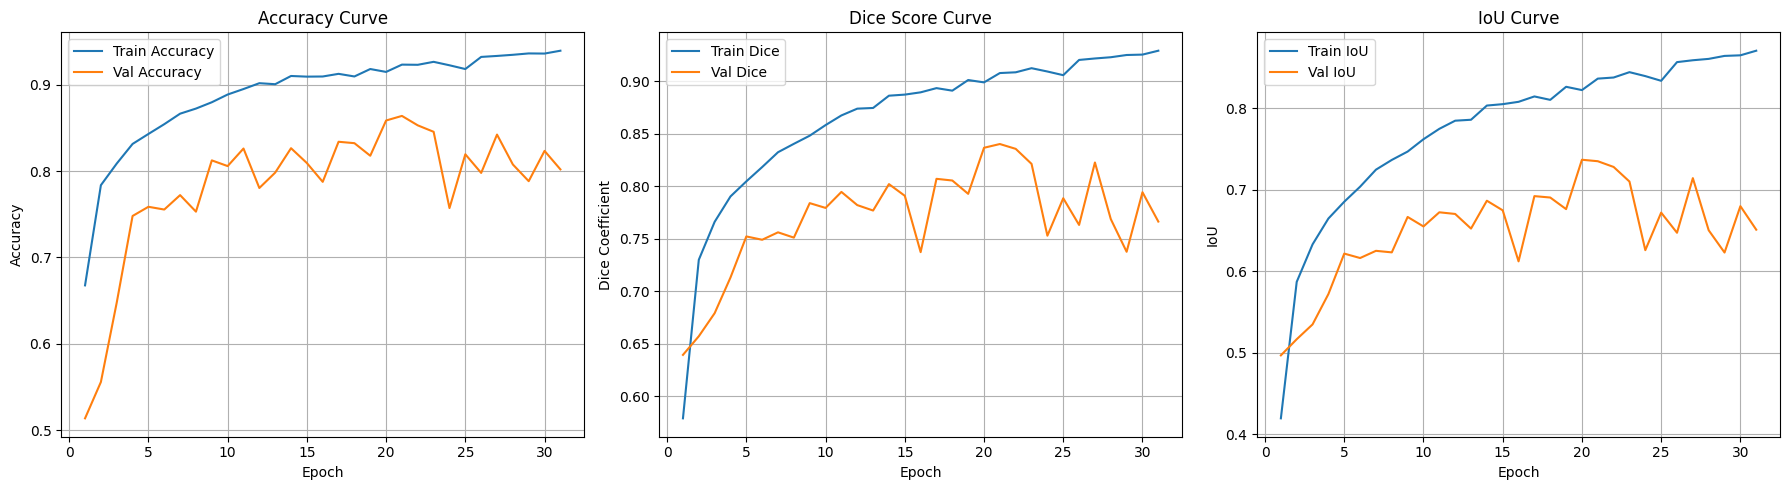

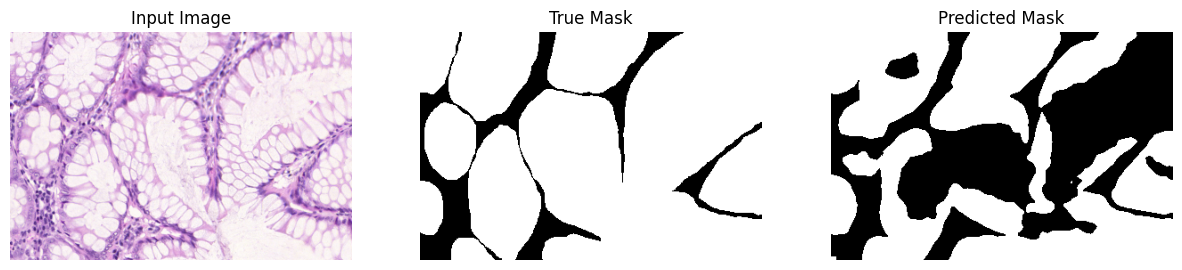

In [3]:
# ============================================================
# BUILD TRAIN / VALIDATION / TEST PIPELINES USING THE GIVEN SPLITS
# ============================================================
def make_dataset(pairs, training=False):
    if not pairs:
        raise ValueError("Cannot build a dataset with zero image-mask pairs.")
    image_paths = [p[0] for p in pairs]
    mask_paths = [p[1] for p in pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(pairs), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)  # held out; not used for model selection

print("\nDataset sizes:")
print("  Train:", len(train_pairs))
print("  Val  :", len(val_pairs))
print("  Test :", len(test_pairs))
print("Input tensor shape:", (IMG_SIZE[0], IMG_SIZE[1], 3))
print("Outputs will be saved to:", OUTPUT_DIR)

# =========================
# METRICS / LOSS
# =========================
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

# =========================================================
# LEARNABLE KERNEL LAYER
# =========================================================
@tf.keras.utils.register_keras_serializable()
class LearnableDepthwiseConv2D(layers.Layer):
    """
    Learnable depthwise kernel bank initialized with:
    - Sobel X
    - Sobel Y
    - Laplacian

    Input:  [B, H, W, C]
    Output: [B, H, W, 3C]
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])

        sobel_x = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)

        sobel_y = np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=np.float32)

        laplacian = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)

        # depthwise kernel shape: [kh, kw, in_channels, channel_multiplier]
        init_kernel = np.zeros((3, 3, c, 3), dtype=np.float32)

        for ch in range(c):
            init_kernel[:, :, ch, 0] = sobel_x
            init_kernel[:, :, ch, 1] = sobel_y
            init_kernel[:, :, ch, 2] = laplacian

        self.kernel = self.add_weight(
            name="kernel",
            shape=(3, 3, c, 3),
            initializer=tf.keras.initializers.Constant(init_kernel),
            trainable=True
        )

        super().build(input_shape)

    def call(self, x):
        return tf.nn.depthwise_conv2d(
            x,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

    def get_config(self):
        config = super().get_config()
        return config


# =========================================================
# LEARNABLE KERNEL BRANCH
# =========================================================
def learnable_kernel_block(x):
    x = LearnableDepthwiseConv2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def merge_with_learnable_kernels(feat, filters, prefix):
    """
    For a single skip tensor:
      original feature
      + learnable-kernel response of that feature
    Then concatenate and compress with 1x1 conv.
    """
    lk = LearnableDepthwiseConv2D(name=f"{prefix}_learnable")(feat)
    x = layers.Concatenate(name=f"{prefix}_concat")([feat, lk])

    x = layers.Conv2D(
        filters,
        1,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{prefix}_compress"
    )(x)
    x = layers.ReLU(name=f"{prefix}_compress_relu")(x)
    return x


# =========================================================
# U-NET BLOCKS
# =========================================================
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p


def up_block(x, skip, skip_learnable, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([x, skip, skip_learnable])
    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x


# =========================================================
# BUILD MODEL
# =========================================================
def build_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1, p1 = down_block(inputs, 32)
    c2, p2 = down_block(p1, 64)
    c3, p3 = down_block(p2, 128)
    c4, p4 = down_block(p3, 256)

    # Learnable-kernel transformed skips
    c1_star = merge_with_learnable_kernels(c1, 32, "c1")
    c2_star = merge_with_learnable_kernels(c2, 64, "c2")
    c3_star = merge_with_learnable_kernels(c3, 128, "c3")
    c4_star = merge_with_learnable_kernels(c4, 256, "c4")

    # Bottleneck
    bottleneck = conv_block(p4, 512)

    # Decoder
    u1 = up_block(bottleneck, c4, c4_star, 256)
    u2 = up_block(u1, c3, c3_star, 128)
    u3 = up_block(u2, c2, c2_star, 64)
    u4 = up_block(u3, c1, c1_star, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_Binary_LearnableKernel")
    return model


model = build_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

model.summary()

# =========================
# CALLBACKS
# =========================
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unet_learnablekernel.keras"),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

# =========================
# TRAIN
# =========================
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Save the trained model; EarlyStopping restores the best validation-Dice weights.
final_model_path = os.path.join(OUTPUT_DIR, "final_unet_learnablekernel.keras")
model.save(final_model_path)
print("Saved trained model:", final_model_path)

# =========================
# PLOTS: ACCURACY, DICE, IOU
# =========================
def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Val Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Val IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(history)

# =========================
# PREDICTION + VISUALIZATION
# =========================
def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

# Show one validation sample
show_prediction(model, val_pairs[0])


Test image 1/16: testB_1.png
  IoU                   : 0.6581
  Recall                : 0.7899
  Precision             : 0.7977
  Dice Coefficient      : 0.7938
  Boundary F1           : 0.4619
  Boundary Recall       : 0.6760
  Boundary Precision    : 0.3508

Test image 2/16: testB_10.png
  IoU                   : 0.6575
  Recall                : 0.8065
  Precision             : 0.7806
  Dice Coefficient      : 0.7934
  Boundary F1           : 0.5595
  Boundary Recall       : 0.6631
  Boundary Precision    : 0.4839

Test image 3/16: testB_11.png
  IoU                   : 0.9632
  Recall                : 0.9853
  Precision             : 0.9773
  Dice Coefficient      : 0.9813
  Boundary F1           : 0.9244
  Boundary Recall       : 0.9359
  Boundary Precision    : 0.9132

Test image 4/16: testB_12.png
  IoU                   : 0.7908
  Recall                : 0.9169
  Precision             : 0.8519
  Dice Coefficient      : 0.8832
  Boundary F1           : 0.5541
  Boundary Recall  

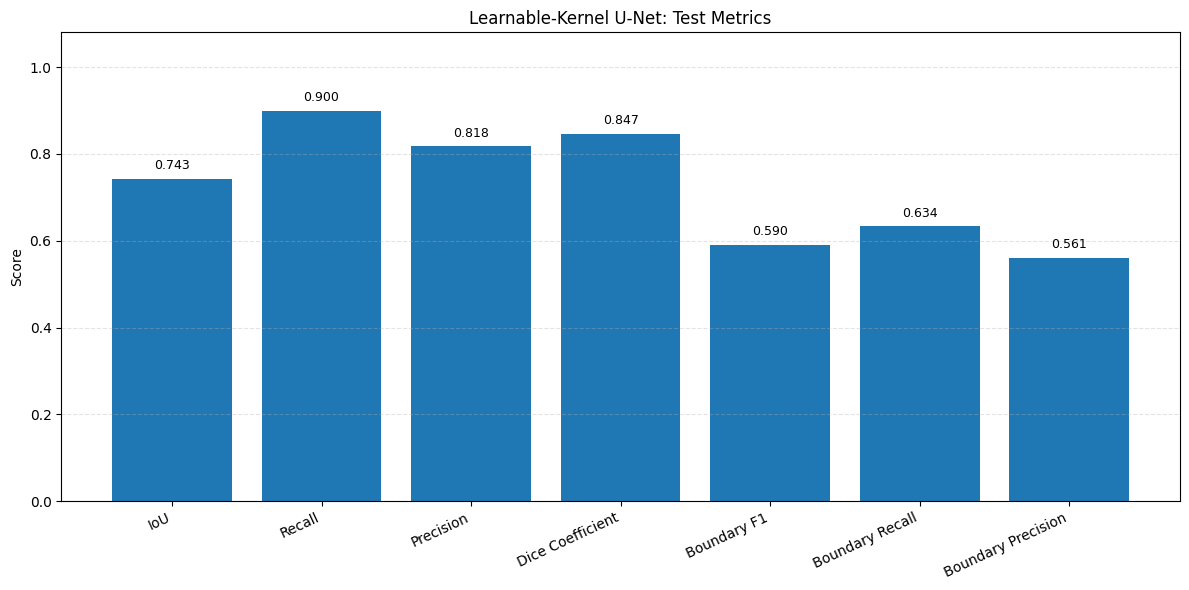

Saved overall graph: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/test_metrics_graph.png


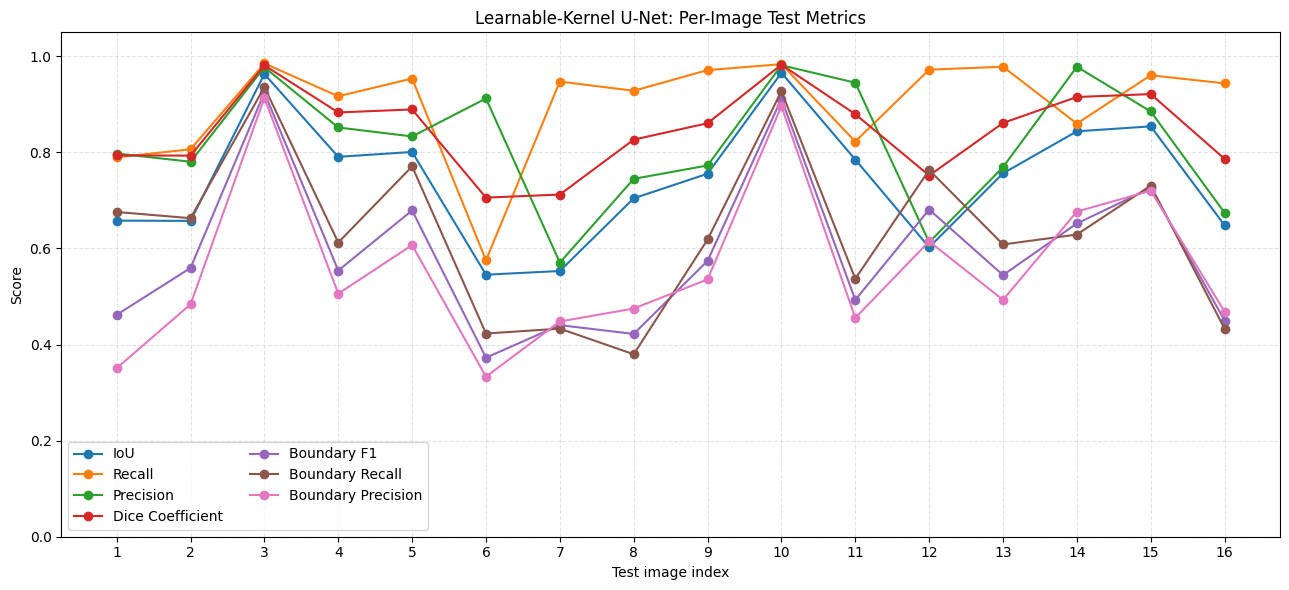

Saved per-image graph: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/test_metrics_per_image_graph.png


In [4]:
# ============================================================
# FINAL TEST EVALUATION: 7 METRICS + PRINTED VALUES + GRAPHS
# Boundary scores are derived from mask folder only.
# Boundary_Mask_GT is deliberately NOT loaded or used.
# ============================================================

import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

PRED_THRESHOLD = 0.5
BOUNDARY_TOLERANCE = int(globals().get("BOUNDARY_TOLERANCE", 2))
OUTPUT_DIR = globals().get(
    "OUTPUT_DIR", "/raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIC_NAMES = [
    "iou", "recall", "precision", "dice_coef",
    "boundary_f1", "boundary_recall", "boundary_precision"
]
DISPLAY_NAMES = [
    "IoU", "Recall", "Precision", "Dice Coefficient",
    "Boundary F1", "Boundary Recall", "Boundary Precision"
]


def extract_binary_boundary(binary_mask):
    """Extract the inner foreground boundary from a 0/1 binary mask."""
    mask = np.asarray(binary_mask, dtype=np.uint8).squeeze()
    eroded = cv2.erode(
        mask,
        np.ones((3, 3), dtype=np.uint8),
        iterations=1,
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    return (mask - eroded).astype(np.uint8)


def calculate_all_metrics(gt_mask, pred_mask, tolerance=2):
    gt = (np.asarray(gt_mask).squeeze() > 0).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shapes differ: GT={gt.shape}, prediction={pred.shape}")

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))

    precision = tp / (tp + fp) if (tp + fp) else (1.0 if (tp + fn) == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if (tp + fp) == 0 else 0.0)
    dice_denominator = 2 * tp + fp + fn
    dice = (2 * tp / dice_denominator) if dice_denominator else 1.0
    iou_denominator = tp + fp + fn
    iou = (tp / iou_denominator) if iou_denominator else 1.0

    # Boundary metrics: both contours come from binary masks, never Boundary_Mask_GT.
    gt_boundary = extract_binary_boundary(gt)
    pred_boundary = extract_binary_boundary(pred)
    gt_count = int(gt_boundary.sum())
    pred_count = int(pred_boundary.sum())

    tolerance = max(0, int(tolerance))
    if tolerance == 0:
        gt_dilated = gt_boundary
        pred_dilated = pred_boundary
    else:
        ksize = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)

    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))

    boundary_precision = (
        matched_pred / pred_count if pred_count > 0
        else (1.0 if gt_count == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / gt_count if gt_count > 0
        else (1.0 if pred_count == 0 else 0.0)
    )
    denom = boundary_precision + boundary_recall
    boundary_f1 = (
        2 * boundary_precision * boundary_recall / denom if denom > 0 else 0.0
    )

    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


if "model" not in globals():
    raise RuntimeError("Trained Keras model variable 'model' was not found.")
if "test_pairs" not in globals() or not test_pairs:
    raise RuntimeError("test_pairs is missing or empty; create the test split first.")
if "load_image_mask" not in globals():
    raise RuntimeError("load_image_mask() is not defined in this notebook.")

rows = []
for idx, (img_path, mask_path) in enumerate(test_pairs, start=1):
    # The loader reads the image and its mask folder pair located at ROOT_DIR/split/mask.
    image, gt_mask = load_image_mask(str(img_path).encode(), str(mask_path).encode())
    probabilities = model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    pred_mask = (np.asarray(probabilities).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
    gt_binary = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)

    scores = calculate_all_metrics(gt_binary, pred_mask, BOUNDARY_TOLERANCE)
    row = {"image": os.path.basename(str(img_path)), **scores}
    rows.append(row)

    print(f"\nTest image {idx}/{len(test_pairs)}: {row['image']}")
    for key, label in zip(METRIC_NAMES, DISPLAY_NAMES):
        print(f"  {label:<22}: {scores[key]:.4f}")

results_df = pd.DataFrame(rows)
mean_scores = results_df[METRIC_NAMES].mean()

print("\n" + "=" * 62)
print("FINAL TEST SCORES (MACRO-AVERAGE OVER IMAGES)")
print("=" * 62)
for key, label in zip(METRIC_NAMES, DISPLAY_NAMES):
    print(f"{label:<24}: {mean_scores[key]:.4f}")
print("=" * 62)
print(f"Images evaluated: {len(results_df)}")
print(f"Boundary tolerance: {BOUNDARY_TOLERANCE} pixels")

# Save metric tables
per_image_csv = os.path.join(OUTPUT_DIR, "test_metrics_per_image.csv")
summary_csv = os.path.join(OUTPUT_DIR, "test_metrics_summary.csv")
results_df.to_csv(per_image_csv, index=False)
summary_df = pd.DataFrame({
    "metric": DISPLAY_NAMES,
    "mean_score": [mean_scores[key] for key in METRIC_NAMES],
})
summary_df.to_csv(summary_csv, index=False)
print("\nSaved per-image CSV:", per_image_csv)
print("Saved summary CSV:", summary_csv)

# Graph 1: final macro-average values with numeric labels
values = [float(mean_scores[key]) for key in METRIC_NAMES]
plt.figure(figsize=(12, 6))
bars = plt.bar(DISPLAY_NAMES, values)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.title("Learnable-Kernel U-Net: Test Metrics")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
             f"{value:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
overall_graph = os.path.join(OUTPUT_DIR, "test_metrics_graph.png")
plt.savefig(overall_graph, dpi=200, bbox_inches="tight")
plt.show()
print("Saved overall graph:", overall_graph)

# Graph 2: values by test image
plt.figure(figsize=(13, 6))
image_numbers = np.arange(1, len(results_df) + 1)
for key, label in zip(METRIC_NAMES, DISPLAY_NAMES):
    plt.plot(image_numbers, results_df[key], marker="o", linewidth=1.5, label=label)
plt.ylim(0, 1.05)
plt.xlabel("Test image index")
plt.ylabel("Score")
plt.title("Learnable-Kernel U-Net: Per-Image Test Metrics")
plt.xticks(image_numbers)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(ncol=2)
plt.tight_layout()
per_image_graph = os.path.join(OUTPUT_DIR, "test_metrics_per_image_graph.png")
plt.savefig(per_image_graph, dpi=200, bbox_inches="tight")
plt.show()
print("Saved per-image graph:", per_image_graph)


In [5]:
# Save predicted masks
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
os.makedirs(PREDICTION_DIR, exist_ok=True)

PRED_THRESHOLD = globals().get("PRED_THRESHOLD", 0.5)

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):

    # Your loader expects byte strings
    image, _ = load_image_mask(
        str(image_path).encode(),
        str(mask_path).encode()
    )

    # Generate prediction (model already uses sigmoid)
    pred_prob = model.predict(
        np.expand_dims(image, axis=0), verbose=0
    )[0, ..., 0]

    pred_mask = (pred_prob >= PRED_THRESHOLD).astype(np.uint8) * 255

    # Save predicted mask as PNG
    filename = f"{os.path.splitext(os.path.basename(str(image_path)))[0]}_prediction.png"
    save_path = os.path.join(PREDICTION_DIR, filename)

    if not cv2.imwrite(save_path, pred_mask):
        raise IOError(f"Failed to save predicted mask: {save_path}")

    print(f"[{idx}/{len(val_pairs)}] Saved: {save_path}")

print(f"\nAll predicted masks saved in:\n{PREDICTION_DIR}")

[1/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_1_prediction.png
[2/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_10_prediction.png
[3/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_11_prediction.png
[4/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_12_prediction.png
[5/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_13_prediction.png
[6/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_14_prediction.png
[7/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_15_prediction.png
[8/16] Saved: /raid/home/dgx1725/warwick_qu_modification3_learnablekernel_outputs/predicted_masks/testA_16_prediction.png
[9/16] Saved: /raid/home/